# 05 · Ten nodes and the two founding duplications

Ten reconstructed nodes: the three founding nodes, the two class I descendants, and the
nested chain `node_6 -> 12 -> 21 -> 32 -> 44` down the class II trunk. The second half
isolates the two founding duplications and asks what chemistry each one gained.

| paper | tree | node |
|---|---|---|
| 0 | `node_1` | common ancestor |
| 1 | `node_2` | class I ancestor |
| 2 | `node_3` | class II ancestor |
| 3, 4 | `node_4`, `node_5` | the two class I descendants |
| 5 | `node_6` | the class II descendant |
| 11, 20, 31, 43 | `node_12`, `node_21`, `node_32`, `node_44` | further down the class II trunk |

Figures use the paper's numbers; tables give the tree id and `node_fig`. Only reconstructed
nodes appear, called by the same density fill as the rest of the folder.

In [1]:
import os
import sys
from pathlib import Path

REPO = Path("../..").resolve()
sys.path.append(str(REPO / "Downstream_Analysis/scripts"))
sys.path.append(str(REPO / "scripts"))

from ancestral_sets import (ASR_MATRIX, REF_MATRIX, PAIRS, FASTA, ASR_TREE, CLASSES,
                            FIGURES, TABLES)

INPUTS = [ASR_MATRIX, REF_MATRIX, PAIRS, FASTA, ASR_TREE, CLASSES]
TABLES_WRITTEN = ["topology", "pairwise_jaccard", "lineage_functional_groups",
                  "dup_chemistry", "shift_plane", "orthogonality",
                  "orthogonality_null_draws", "orthogonality_variants",
                  "pca_coordinates", "pca_variance", "orthogonality_crosschecks",
                  "orthogonality_loss_definitions", "loss_selectivity",
                  "duplication_branches", "table1_nodes", "table1_stages"]
FIGURES_WRITTEN = ["lineage", "node_or_class", "pairwise_overlap", "upset",
                   "lineage_node_descriptors"]

for path in INPUTS:
    print("input  ", os.path.relpath(path, REPO))
print("tables ", os.path.relpath(TABLES, REPO), TABLES_WRITTEN)
print("figures", os.path.relpath(FIGURES, REPO), FIGURES_WRITTEN)

input   Downstream_Analysis/predictions/aggregated/ASR_Predictions/asr_median_probability_wide.csv
input   Downstream_Analysis/predictions/aggregated/Reference_Tree_Predictions/reference_median_probability_wide.csv
input   Model_Inputs/Data_Preparation/processed/m2or_pairs_model.csv
input   Phylogenetic_Analysis/data/ReferenceTree/PF13853.9606_7955_7740_7764_75743_137246.fa
input   Ancestral_Receptor_Reconstruction/human_tree_asr_hagfish_outgroup/PF13853_9606.7764.mafft.lg.treefile.rooted.withinternalnames
input   Phylogenetic_Analysis/data/HumanTree/human433_OR_classes.csv
tables  Downstream_Analysis/ancestral_receptors/results ['topology', 'pairwise_jaccard', 'lineage_functional_groups', 'dup_chemistry', 'shift_plane', 'orthogonality', 'orthogonality_null_draws', 'orthogonality_variants', 'pca_coordinates', 'pca_variance', 'orthogonality_crosschecks', 'orthogonality_loss_definitions', 'loss_selectivity', 'duplication_branches', 'table1_nodes', 'table1_stages']
figures Downstream_Anal

In [2]:
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Crippen, Descriptors, rdMolDescriptors
from scipy.spatial.distance import pdist, squareform
from scipy.stats import fisher_exact, kruskal, levene

from plotting_functions import custom_plots, FIGSIZE
from ancestral_figures import box_with_points
from ancestral_sets import (load_ancestral, functional_groups, descriptors, node_topology,
                            node_sets, asr_tree, density_grid, figure_node, save_fig,
                            save_table, FG_SMARTS, DESCRIPTORS, TEN_NODES)
plt.rcParams.update(custom_plots())

COMMON_COL, CLASS1_COL, CLASS2_COL = "#5F6A72", "#7f1734", "#557c99"
# ten pastel colours, one per node, in TEN_NODES order
PAL = ["#7babe6", "#72cdad", "#f4c561", "#61b261", "#8f85c8",
       "#ee8e8e", "#f1adc7", "#f3a181", "#61bfdc", "#c29161"]
NCOL = {n: PAL[i] for i, n in enumerate(TEN_NODES)}
FIG_TICKS = [str(figure_node(n)) for n in TEN_NODES]

topo = node_topology(TEN_NODES)
sets = node_sets(TEN_NODES)
print(topo.to_string(index=False))
save_table(topo, "topology")

 node  node_fig  parent  parent_fig  depth  branch_len  n_leaves  frac_class_I OR_class  n_ligands  n_retained  n_gained  n_lost ancestors_in_set
    1         0  node_0        <NA>      1    1.512110       433         0.143    mixed         21         NaN       NaN     NaN                 
    2         1  node_1           0      2    0.487478        62         1.000  Class_I         21         4.0      17.0    17.0                1
    3         2  node_1           0      2    0.357385       371         0.000 Class_II          8         7.0       1.0    14.0                1
    4         3  node_2           1      3    0.473190        55         1.000  Class_I         23        12.0      11.0     9.0              1;2
    5         4  node_2           1      3    0.737785         7         1.000  Class_I         21        13.0       8.0     8.0              1;2
    6         5  node_3           2      3    0.547405       370         0.000 Class_II         27         7.0      20.0    

## Where the ten nodes sit

Depth from the root against repertoire size, each node joined to its nearest ancestor in the
set; the OR class of each node from its descendant human receptors (≥ 90% class I is
class I, ≤ 10% is class II, anything between is mixed).

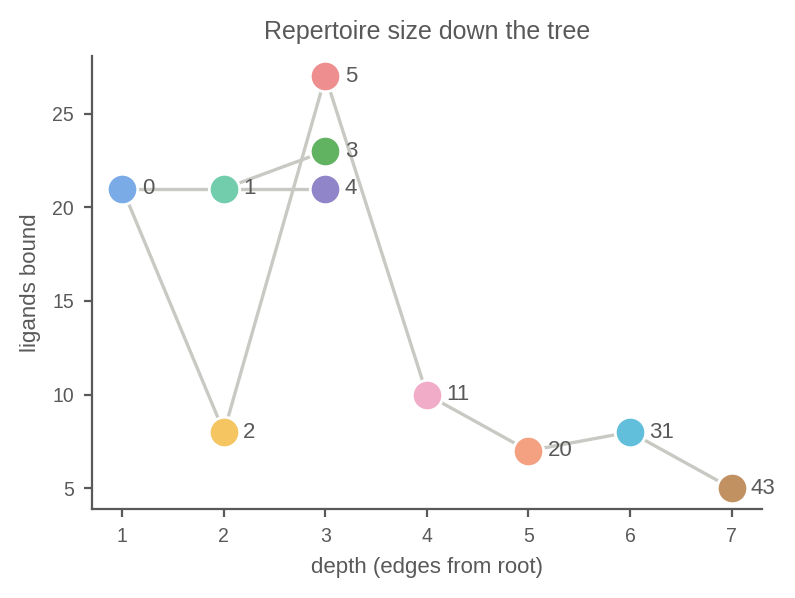

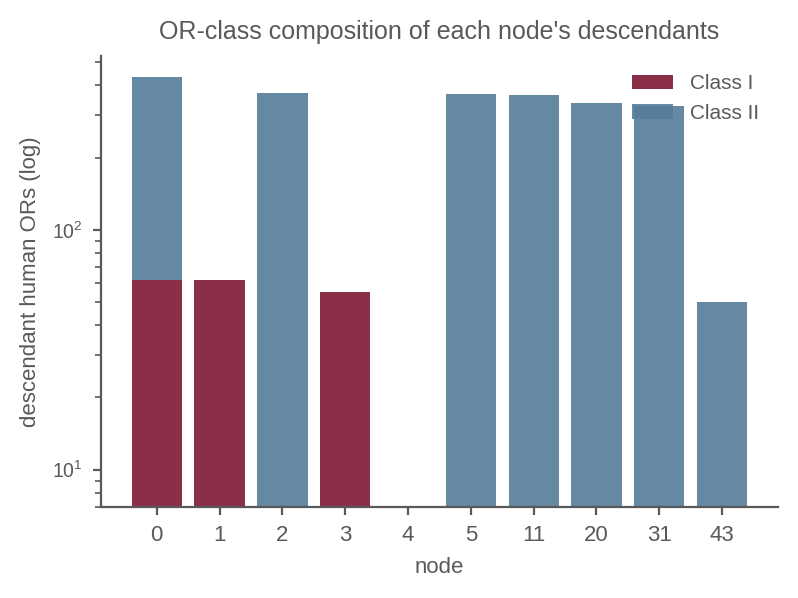

In [3]:
nearest = {}
for r in topo.itertuples():
    within = [int(a) for a in r.ancestors_in_set.split(";") if a]
    nearest[r.node] = (max(within, key=lambda m: int(topo.loc[topo.node == m, "depth"].iloc[0]))
                       if within else None)
depth = dict(zip(topo.node, topo.depth))
nlig = dict(zip(topo.node, topo.n_ligands))

fig, ax = plt.subplots(figsize=FIGSIZE)
for n, p in nearest.items():
    if p is not None:
        ax.plot([depth[p], depth[n]], [nlig[p], nlig[n]], color="#c9c9c4", lw=1.2, zorder=1)
for r in topo.itertuples():
    ax.scatter(r.depth, r.n_ligands, s=120, color=NCOL[r.node], zorder=3,
               edgecolor="white", lw=1.0)
    ax.annotate(str(figure_node(r.node)), (r.depth, r.n_ligands), xytext=(7, 0),
                textcoords="offset points", va="center", fontsize=8)
ax.set_xlabel("depth (edges from root)"); ax.set_ylabel("ligands bound")
ax.set_title("Repertoire size down the tree", fontsize=9)
plt.tight_layout(); save_fig(fig, "lineage"); plt.show()

fig, ax = plt.subplots(figsize=FIGSIZE)
x = np.arange(len(topo))
n_i = topo.frac_class_I * topo.n_leaves
n_ii = (1 - topo.frac_class_I) * topo.n_leaves
ax.bar(x, n_i, color=CLASS1_COL, label="Class I", alpha=0.9)
ax.bar(x, n_ii, bottom=n_i, color=CLASS2_COL, label="Class II", alpha=0.9)
ax.set_yscale("log"); ax.set_ylabel("descendant human ORs (log)")
ax.set_xticks(x); ax.set_xticklabels([str(figure_node(n)) for n in topo.node], fontsize=8)
ax.set_xlabel("node")
ax.legend(frameon=False, fontsize=7.5)
ax.set_title("OR-class composition of each node's descendants", fontsize=9)
plt.tight_layout(); save_fig(fig, "node_or_class"); plt.show()

## Overlap between the ten repertoires

Pairwise intersection and Jaccard similarity (`results/pairwise_jaccard.csv`, rows and
columns by tree id), and which combinations of nodes share a ligand.

union of the ten: 61 ligands
bound by all ten: 1 ligands


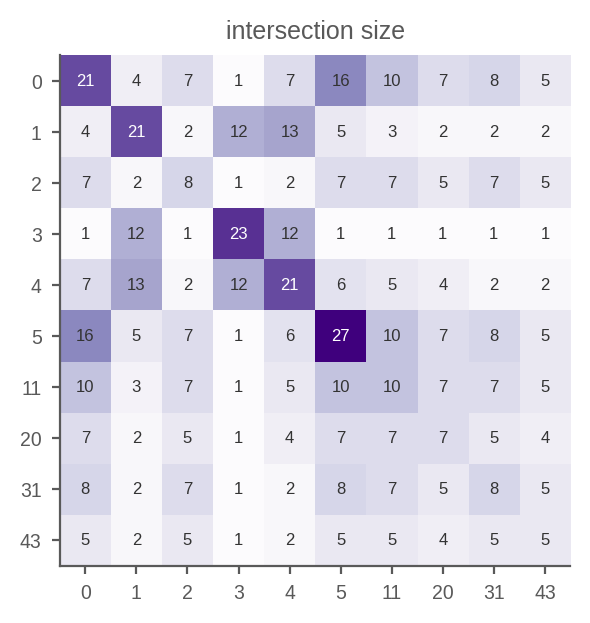

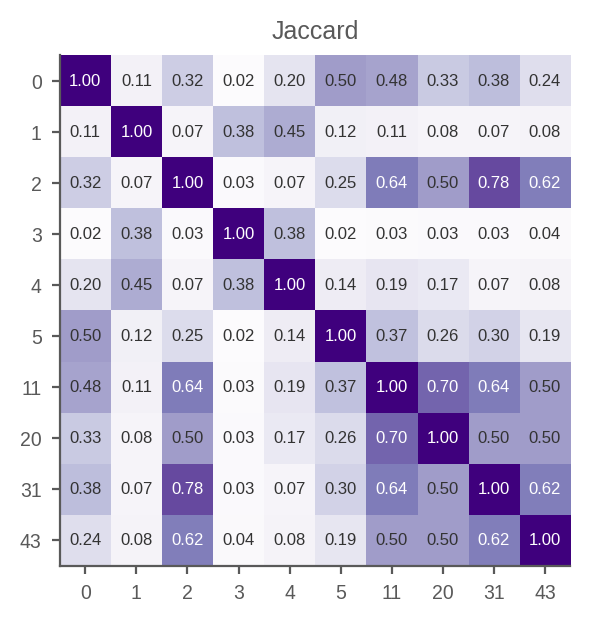

In [4]:
J = pd.DataFrame(index=TEN_NODES, columns=TEN_NODES, dtype=float)
I = pd.DataFrame(index=TEN_NODES, columns=TEN_NODES, dtype=int)
for a in TEN_NODES:
    for b in TEN_NODES:
        inter = len(sets[a] & sets[b]); union = len(sets[a] | sets[b])
        I.loc[a, b] = inter
        J.loc[a, b] = inter / union if union else 0.0
jaccard = J.round(4).reset_index().rename(columns={"index": "node"})
jaccard.insert(1, "node_fig", [figure_node(n) for n in TEN_NODES])
save_table(jaccard, "pairwise_jaccard")

union_all = sorted(set().union(*sets.values()))
print(f"union of the ten: {len(union_all)} ligands")
print(f"bound by all ten: {len(set.intersection(*sets.values()))} ligands")

figures, axes = zip(*[plt.subplots(figsize=FIGSIZE, layout="constrained") for _ in range(2)])
for ax, M, title, fmt in [(axes[0], I.astype(float), "intersection size", ".0f"),
                          (axes[1], J.astype(float), "Jaccard", ".2f")]:
    ax.imshow(M.values, cmap="Purples")
    ax.set_xticks(range(len(TEN_NODES))); ax.set_yticks(range(len(TEN_NODES)))
    ax.set_xticklabels(FIG_TICKS, fontsize=7)
    ax.set_yticklabels(FIG_TICKS, fontsize=7)
    cut = M.values.max() * 0.6
    for i in range(len(TEN_NODES)):
        for j in range(len(TEN_NODES)):
            ax.text(j, i, format(M.values[i, j], fmt), ha="center", va="center",
                    fontsize=6, color="white" if M.values[i, j] > cut else "#333")
    ax.set_title(title, fontsize=9)
save_fig(figures[0], "pairwise_overlap_intersection"); save_fig(figures[1], "pairwise_overlap_jaccard"); plt.show()

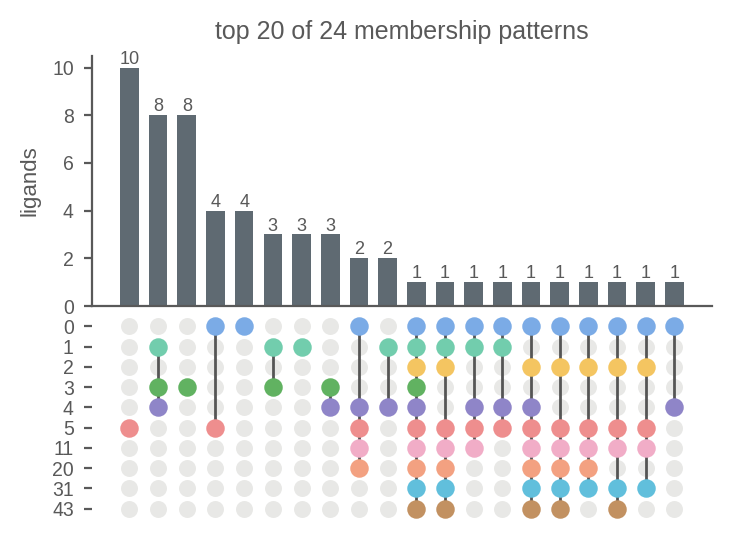

In [5]:
member = [tuple(s in sets[n] for n in TEN_NODES) for s in union_all]
counts = pd.Series(Counter(member)).sort_index(ascending=False)
counts = counts.sort_values(ascending=False, kind="stable")
top = counts.head(20)

fig = plt.figure(figsize=FIGSIZE)
gs = fig.add_gridspec(2, 1, height_ratios=[2.0, 1.6], hspace=0.05)
axb = fig.add_subplot(gs[0]); axm = fig.add_subplot(gs[1], sharex=axb)
xs = np.arange(len(top))
axb.bar(xs, top.values, color="#5F6A72", width=0.65)
for xi, v in zip(xs, top.values):
    axb.text(xi, v, str(v), ha="center", va="bottom", fontsize=6.5)
axb.set_ylabel("ligands"); axb.tick_params(labelbottom=False)
for yi, n in enumerate(TEN_NODES):
    axm.scatter(xs, [yi] * len(xs), s=26, color="#e8e8e6", zorder=1)
    on = [xi for xi, m in zip(xs, top.index) if m[yi]]
    axm.scatter(on, [yi] * len(on), s=32, color=NCOL[n], zorder=3)
for xi, m in zip(xs, top.index):
    idx = [yi for yi in range(len(TEN_NODES)) if m[yi]]
    if len(idx) > 1:
        axm.plot([xi, xi], [min(idx), max(idx)], color="#555", lw=1.0, zorder=2)
axm.set_yticks(range(len(TEN_NODES)))
axm.set_yticklabels(FIG_TICKS, fontsize=7)
axm.set_xticks([]); axm.invert_yaxis()
for sp in ["top", "right", "bottom", "left"]:
    axm.spines[sp].set_visible(False)
axb.set_title(f"top {len(top)} of {len(counts)} membership patterns", fontsize=9)
save_fig(fig, "upset"); plt.show()

## Gains, losses and chemistry per node

Gains and losses against the immediate parent, which is taken from the full ASR matrix and
need not be one of the ten (`results/topology.csv`; Extended Data Fig. 6a). Then
descriptors per node and the
functional-group share of each repertoire, `results/lineage_functional_groups.csv` (one column per
tree id; Fig. 3e, Extended Data Fig. 6b).

In [6]:
gl = topo.dropna(subset=["n_gained"])
print(gl[["node", "node_fig", "parent", "n_ligands", "n_retained", "n_gained", "n_lost"]]
      .to_string(index=False))

 node  node_fig  parent  n_ligands  n_retained  n_gained  n_lost
    2         1  node_1         21         4.0      17.0    17.0
    3         2  node_1          8         7.0       1.0    14.0
    4         3  node_2         23        12.0      11.0     9.0
    5         4  node_2         21        13.0       8.0     8.0
    6         5  node_3         27         7.0      20.0     1.0
   12        11  node_6         10        10.0       0.0    17.0
   21        20 node_12          7         7.0       0.0     3.0
   32        31 node_21          8         5.0       3.0     2.0
   44        43 node_32          5         5.0       0.0     3.0


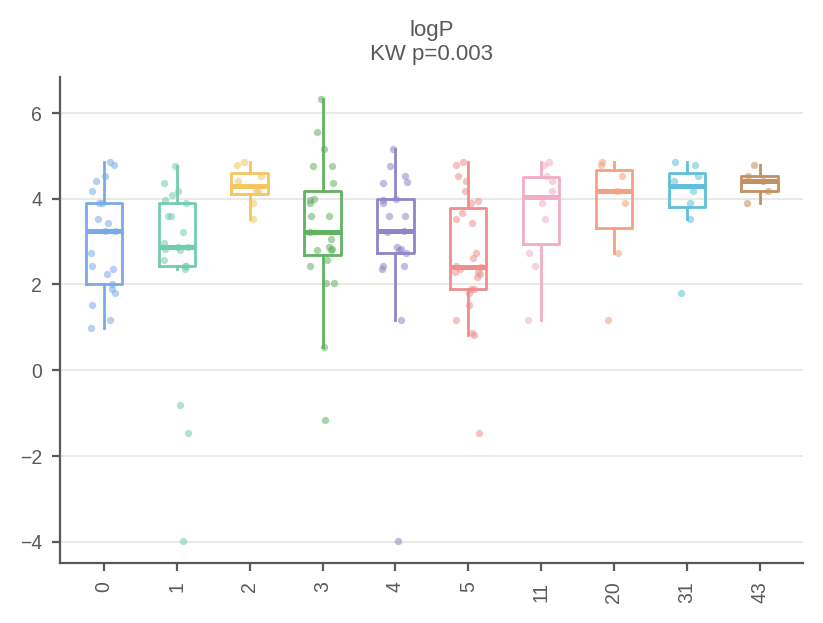

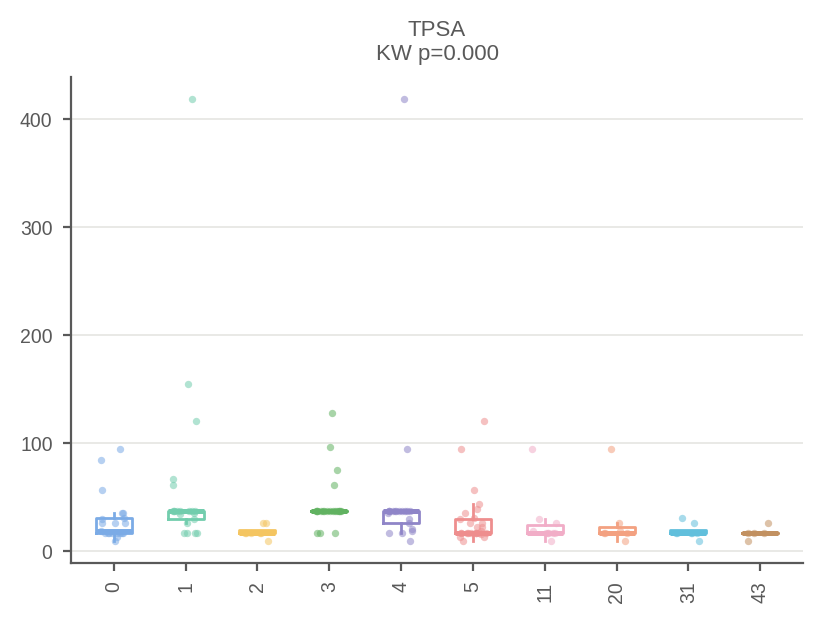

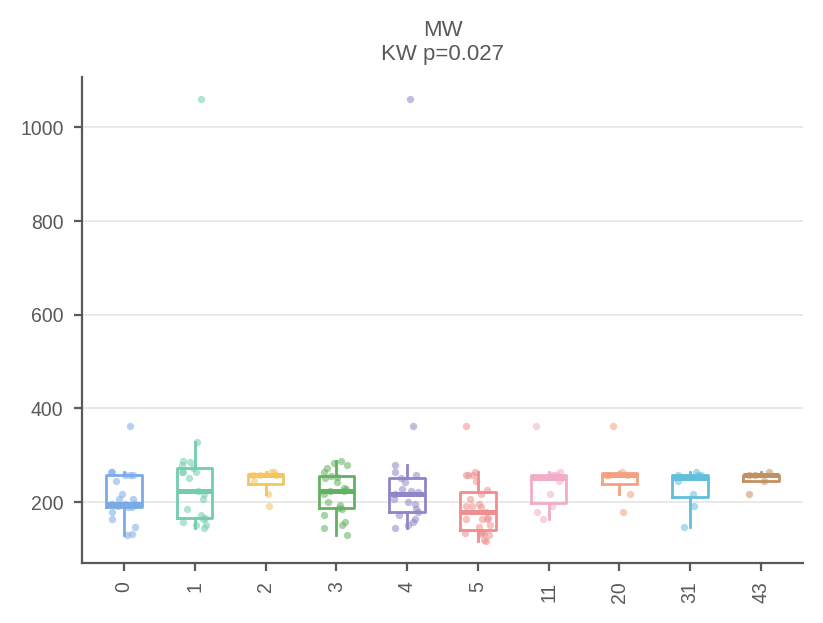

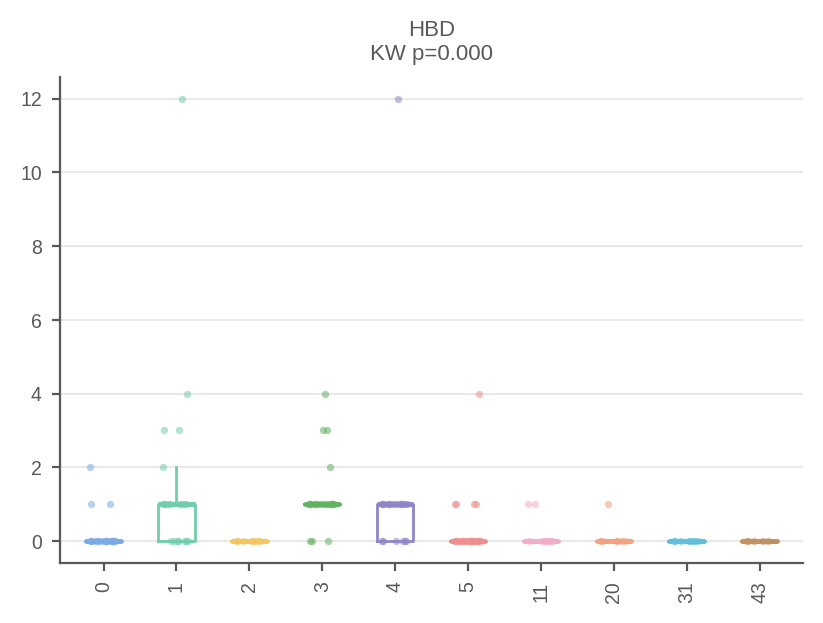

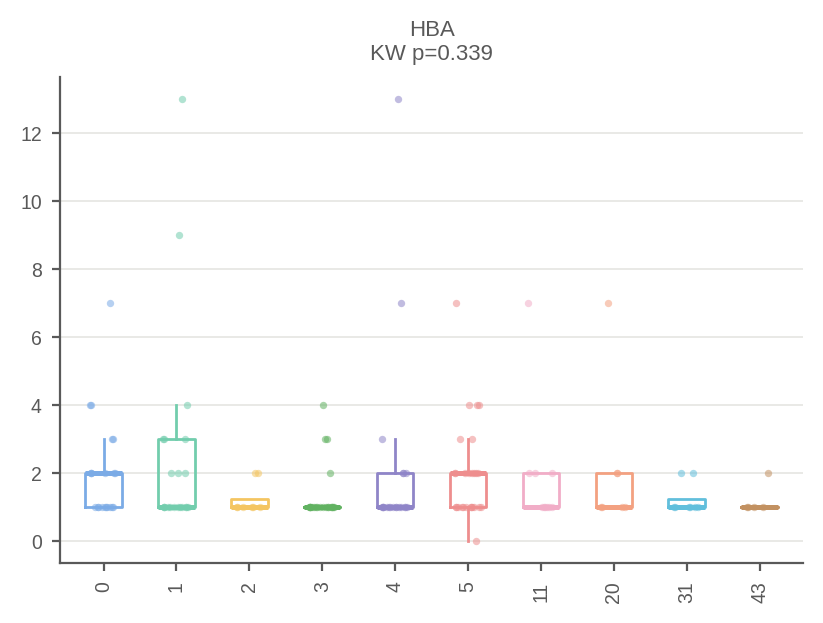

                    0     1     2     3     4     5    11    20    31    43
carboxylic_acid   0.0  47.6   0.0  82.6  57.1   0.0   0.0   0.0   0.0   0.0
alcohol           4.8  14.3   0.0   4.3  14.3   3.7  10.0  14.3   0.0   0.0
aldehyde          4.8   9.5   0.0   4.3   4.8   3.7   0.0   0.0   0.0   0.0
ketone           42.9  14.3  62.5   8.7   4.8  37.0  50.0  42.9  62.5  60.0
ester            28.6   9.5  25.0   0.0  14.3  18.5  20.0  28.6  12.5  20.0
ether            33.3  19.0  12.5   4.3  23.8  25.9  40.0  42.9  12.5  20.0
amine             0.0  14.3   0.0   4.3   4.8   7.4   0.0   0.0   0.0   0.0
amide             4.8   4.8   0.0   4.3   4.8   0.0   0.0   0.0   0.0   0.0
aromatic_ring    61.9  33.3  50.0   8.7  23.8  74.1  60.0  57.1  62.5  60.0
phenol            4.8  14.3   0.0   8.7   4.8   3.7  10.0   0.0   0.0   0.0
nitrile           0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0
alkene           57.1  33.3  25.0  13.0  38.1  33.3  50.0  42.9  25.0  20.0


In [7]:
chem = descriptors(union_all).merge(functional_groups(union_all), on="SMILES")
FG_COLS = list(FG_SMARTS)

figures, axes = zip(*[plt.subplots(figsize=FIGSIZE, layout="constrained") for _ in range(len(DESCRIPTORS))])
for ax, d in zip(axes, DESCRIPTORS):
    data = [chem[chem.SMILES.isin(sets[n])][d].dropna().values for n in TEN_NODES]
    box_with_points(ax, data, [NCOL[n] for n in TEN_NODES])
    h, p = kruskal(*data)
    ax.set_title(f"{d}\nKW p={p:.3f}", fontsize=8)
    ax.set_xticks(range(1, len(TEN_NODES) + 1))
    ax.set_xticklabels(FIG_TICKS, fontsize=6, rotation=90)
    ax.tick_params(labelsize=7)
for figure, d in zip(figures, DESCRIPTORS): save_fig(figure, f"lineage_node_descriptors_{d}")
plt.show()

prev = pd.DataFrame({n: chem[chem.SMILES.isin(sets[n])][FG_COLS].mean() * 100
                     for n in TEN_NODES})
print(prev.round(1).rename(columns=dict(zip(TEN_NODES, FIG_TICKS))).to_string())
save_table(prev.reset_index().rename(columns={"index": "functional_group"}),
           "lineage_functional_groups")

## The two founding duplications

- **dup1**, `node_1 -> node_2` (paper 0 → 1): the class I branch out of the common ancestor.
- **dup2**, `node_3 -> node_6` (paper 2 → 5): the class II branch. `node_3`'s other child is
  the single receptor `9606.A6NND4` on a long branch next to the outgroup, a long-branch
  attraction geometry, so it is set aside.

Each gain set (ligands the child binds and its parent does not) is tested for carboxylic
acids and aromatic rings by Fisher's exact test against two backgrounds: the full
754-molecule panel and the union of the ten nodes' repertoires, each without the gain set
itself. Writes `results/dup_chemistry.csv` (Supplementary Table 8).

In [8]:
anc = load_ancestral()
PANEL = sorted(anc.smiles_map["SMILES"].unique())
fg_panel = functional_groups(PANEL).set_index("SMILES")

DUPS = {
    "dup1": dict(parent=1, child=2, col=CLASS1_COL),
    "dup2": dict(parent=3, child=6, col=CLASS2_COL),
}
for d in DUPS.values():
    d["parent_set"] = sets[d["parent"]]
    d["child_set"] = sets[d["child"]]
    d["gained"] = sorted(d["child_set"] - d["parent_set"])
    d["branch"] = f"node_{d['parent']} -> node_{d['child']}"
    d["branch_fig"] = f"{figure_node(d['parent'])} -> {figure_node(d['child'])}"

rows = []
for k, d in DUPS.items():
    for bg_name, bg in [("full panel", PANEL), ("ten-node universe", union_all)]:
        bgset = [s for s in bg if s not in d["gained"]]
        for grp in ["carboxylic_acid", "aromatic_ring"]:
            a = int(fg_panel.loc[d["gained"], grp].sum()); b = len(d["gained"]) - a
            c = int(fg_panel.loc[bgset, grp].sum()); e = len(bgset) - c
            orr, pv = fisher_exact([[a, b], [c, e]])
            rows.append({"duplication": k, "branch": d["branch"], "branch_fig": d["branch_fig"],
                         "background": f"{bg_name} ({len(bgset)})",
                         "group": grp, "n_gained": len(d["gained"]), "k": a,
                         "pct_gained": round(100 * a / len(d["gained"]), 1),
                         "pct_background": round(100 * c / len(bgset), 1),
                         "odds_ratio": round(orr, 2), "P": float(f"{pv:.2g}")})
dup_chem = pd.DataFrame(rows)
print(dup_chem.to_string(index=False))
save_table(dup_chem, "dup_chemistry")

duplication           branch branch_fig             background           group  n_gained  k  pct_gained  pct_background  odds_ratio        P
       dup1 node_1 -> node_2     0 -> 1       full panel (737) carboxylic_acid        17 10        58.8            10.2       12.61 0.000002
       dup1 node_1 -> node_2     0 -> 1       full panel (737)   aromatic_ring        17  5        29.4            30.9        0.93 1.000000
       dup1 node_1 -> node_2     0 -> 1 ten-node universe (44) carboxylic_acid        17 10        58.8            25.0        4.29 0.018000
       dup1 node_1 -> node_2     0 -> 1 ten-node universe (44)   aromatic_ring        17  5        29.4            50.0        0.42 0.170000
       dup2 node_3 -> node_6     2 -> 5       full panel (734) carboxylic_acid        20  0         0.0            11.6        0.00 0.150000
       dup2 node_3 -> node_6     2 -> 5       full panel (734)   aromatic_ring        20 16        80.0            29.6        9.53 0.000006
       dup2 n

## The shift in descriptor space

Every panel molecule is described by 13 RDKit descriptors, standardised over the panel. A
duplication's shift vector is the centroid of what it gained minus the centroid of its
parent's repertoire. `results/shift_plane.csv` gives both vectors in the plane they
span, so an angle drawn from it is the 13-dimensional angle, plus the five descriptors that
load most on that plane (Extended Data Fig. 6c).

In [9]:
D13 = ["MolWt", "LogP", "TPSA", "HBD", "HBA", "RotB", "AromaticRings", "FracCsp3",
       "HeavyAtoms", "RingCount", "MolMR", "BertzCT", "nO"]


def desc13(smi):
    m = Chem.MolFromSmiles(smi)
    if m is None:
        return [np.nan] * 13
    return [Descriptors.MolWt(m), Crippen.MolLogP(m), Descriptors.TPSA(m),
            rdMolDescriptors.CalcNumHBD(m), rdMolDescriptors.CalcNumHBA(m),
            rdMolDescriptors.CalcNumRotatableBonds(m), rdMolDescriptors.CalcNumAromaticRings(m),
            rdMolDescriptors.CalcFractionCSP3(m), m.GetNumHeavyAtoms(),
            rdMolDescriptors.CalcNumRings(m), Crippen.MolMR(m), Descriptors.BertzCT(m),
            sum(1 for a in m.GetAtoms() if a.GetSymbol() == "O")]


X13 = pd.DataFrame({s: desc13(s) for s in PANEL}).T
X13.columns = D13
Z13 = (X13 - X13.mean()) / X13.std(ddof=0)


def angle(a, b):
    cos = a @ b / (np.linalg.norm(a) * np.linalg.norm(b))
    return np.degrees(np.arccos(np.clip(cos, -1, 1)))


def centroid(smiles):
    return Z13.loc[sorted(smiles), D13].mean().values


v1 = centroid(DUPS["dup1"]["gained"]) - centroid(DUPS["dup1"]["parent_set"])
v2 = centroid(DUPS["dup2"]["gained"]) - centroid(DUPS["dup2"]["parent_set"])
OBS_ANGLE = angle(v1, v2)
cos_theta = v1 @ v2 / (np.linalg.norm(v1) * np.linalg.norm(v2))
print(f"|v1| = {np.linalg.norm(v1):.3f}   |v2| = {np.linalg.norm(v2):.3f}   (panel SD units)")
print(f"cosine = {cos_theta:+.4f}   angle = {OBS_ANGLE:.2f} deg")

basis = np.linalg.qr(np.column_stack([v1, v2]))[0]
a1, a2 = v1 @ basis, v2 @ basis
print(f"angle in the drawn plane = {angle(a1, a2):.2f} deg")

|v1| = 3.337   |v2| = 3.729   (panel SD units)
cosine = -0.1162   angle = 96.67 deg
angle in the drawn plane = 96.67 deg


In [10]:
# the five descriptors that load most on the plane, drawn as faint axes on the panel
load = pd.DataFrame({"x": basis[:, 0], "y": basis[:, 1]}, index=D13)
top_load = load.abs().max(axis=1).sort_values(ascending=False, kind="stable").head(5).index
plane = pd.concat([
    pd.DataFrame({"item": ["dup1", "dup2"], "kind": "shift", "x": [a1[0], a2[0]], "y": [a1[1], a2[1]]}),
    pd.DataFrame({"item": list(top_load), "kind": "descriptor",
                  "x": load.loc[top_load, "x"].values, "y": load.loc[top_load, "y"].values}),
], ignore_index=True)
print(plane.round(3).to_string(index=False))
save_table(plane, "shift_plane")

    item       kind      x      y
    dup1      shift -3.337  0.000
    dup2      shift  0.433  3.703
     HBD descriptor -0.539  0.178
    TPSA descriptor -0.474  0.209
    LogP descriptor  0.131 -0.445
    RotB descriptor -0.390  0.095
FracCsp3 descriptor -0.279 -0.375


## The angle against a null

Molecules in the panel share bulk chemistry, so any two shifts tend to point the same way.
The null draws random gain sets of the same two sizes from the panel (2,000 draws, seed 0),
keeps the two parent centroids, and recomputes the angle; the empirical P is the share of
draws at least as close to 90° as the observed angle. Leave-one-descriptor-out and the
acid–aromatic correlation over the panel are reported beside it. Writes
`results/orthogonality.csv` and the draws, `results/orthogonality_null_draws.csv`
(Extended Data Fig. 6d).

In [11]:
N_NULL = 2000
pan = np.array(PANEL)
n1, n2 = len(DUPS["dup1"]["gained"]), len(DUPS["dup2"]["gained"])
c1 = centroid(DUPS["dup1"]["parent_set"])
c2 = centroid(DUPS["dup2"]["parent_set"])

rng = np.random.default_rng(0)
null = np.array([angle(Z13.loc[rng.choice(pan, n1, replace=False), D13].mean().values - c1,
                       Z13.loc[rng.choice(pan, n2, replace=False), D13].mean().values - c2)
                 for _ in range(N_NULL)])
n_close = int((np.abs(null - 90) <= abs(OBS_ANGLE - 90)).sum())
p_emp = n_close / N_NULL
print(f"observed            {OBS_ANGLE:.1f} deg")
print(f"null median         {np.median(null):.1f} deg   IQR {np.percentile(null, 25):.1f}-"
      f"{np.percentile(null, 75):.1f}   min {null.min():.1f}   max {null.max():.1f}")
print(f"as close to 90 deg  {n_close} / {N_NULL}   (p = {p_emp:.4f})")

loo = [angle(np.delete(v1, i), np.delete(v2, i)) for i in range(len(D13))]
print(f"leave-one-descriptor-out  {min(loo):.1f}-{max(loo):.1f} deg")

phi = np.corrcoef(fg_panel["carboxylic_acid"], fg_panel["aromatic_ring"])[0, 1]
ac, ar = fg_panel["carboxylic_acid"].astype(bool), fg_panel["aromatic_ring"].astype(bool)
print(f"phi(acid, aromatic) over the panel = {phi:+.3f}   "
      f"{100 * ar[ac].mean():.0f}% of acids aromatic, {100 * ac[ar].mean():.0f}% of aromatics acids")

save_table(pd.DataFrame({"observed_angle": [round(OBS_ANGLE, 1)],
                         "null_median": [round(float(np.median(null)), 1)],
                         "null_q25": [round(float(np.percentile(null, 25)), 1)],
                         "null_q75": [round(float(np.percentile(null, 75)), 1)],
                         "p_empirical": [p_emp], "n_draws": [N_NULL],
                         "loo_min": [round(min(loo), 1)], "loo_max": [round(max(loo), 1)],
                         "phi_acid_aromatic": [round(float(phi), 3)]}),
           "orthogonality")

save_table(pd.DataFrame({"draw": np.arange(N_NULL), "angle": null}), "orthogonality_null_draws")

observed            96.7 deg
null median         33.3 deg   IQR 27.8-39.9   min 11.7   max 78.2
as close to 90 deg  0 / 2000   (p = 0.0000)
leave-one-descriptor-out  90.2-102.5 deg
phi(acid, aromatic) over the panel = -0.111   16% of acids aromatic, 6% of aromatics acids


## Other definitions of the angle

The angle after whitening the 13 descriptors by their panel correlation (Mahalanobis), with
its own null; with both branches referenced to node 0; and between the raw gain centroids.
Only the first two have a null. Writes `results/orthogonality_variants.csv`.

In [12]:
corr = np.corrcoef(Z13[D13].values.T)
off = corr[np.triu_indices(len(D13), 1)]
print(f"descriptor correlations: max |r| = {np.abs(off).max():.2f}, mean |r| = {np.abs(off).mean():.2f}")

W = np.linalg.inv(np.linalg.cholesky(corr))
rng_white = np.random.default_rng(0)
null_w = np.array([angle(W @ (Z13.loc[rng_white.choice(pan, n1, replace=False), D13].mean().values - c1),
                         W @ (Z13.loc[rng_white.choice(pan, n2, replace=False), D13].mean().values - c2))
                   for _ in range(N_NULL)])
obs_w = angle(W @ v1, W @ v2)

variants = pd.DataFrame([
    {"variant": "Euclidean, parent-referenced", "angle": round(OBS_ANGLE, 1),
     "null_median": round(float(np.median(null)), 1), "null_max": round(float(null.max()), 1),
     "draws_ge_observed": int((null >= OBS_ANGLE).sum())},
    {"variant": "whitened (Mahalanobis, panel correlation)", "angle": round(obs_w, 1),
     "null_median": round(float(np.median(null_w)), 1), "null_max": round(float(null_w.max()), 1),
     "draws_ge_observed": int((null_w >= obs_w).sum())},
    {"variant": "both branches referenced to node 0",
     "angle": round(angle(v1, centroid(DUPS["dup2"]["gained"]) - c1), 1),
     "null_median": None, "null_max": None, "draws_ge_observed": None},
    {"variant": "raw gain centroids, no parent subtracted",
     "angle": round(angle(centroid(DUPS["dup1"]["gained"]), centroid(DUPS["dup2"]["gained"])), 1),
     "null_median": None, "null_max": None, "draws_ge_observed": None},
])
print(variants.to_string(index=False))
save_table(variants, "orthogonality_variants")

descriptor correlations: max |r| = 0.98, mean |r| = 0.38


                                  variant  angle  null_median  null_max  draws_ge_observed
             Euclidean, parent-referenced   96.7         33.3      78.2                0.0
whitened (Mahalanobis, panel correlation)   88.5         45.6      73.9                0.0
       both branches referenced to node 0  108.0          NaN       NaN                NaN
 raw gain centroids, no parent subtracted   72.8          NaN       NaN                NaN


## PCA view and cross-checks

A PCA of the panel in the same 13 descriptors: `results/pca_coordinates.csv` (PC1, PC2 and
membership of each parent repertoire and gain set) and `results/pca_variance.csv`
(Extended Data Fig. 6e). A PCA plane is a projection, so the share of each shift it captures
is reported. Two cross-checks: PERMANOVA on the 13 descriptors between the two gain
sets (4,999 permutations) with a dispersion check, and the angle after regressing
carboxylic-acid and aromatic-ring flags out of every descriptor, with its null. Writes
`results/orthogonality_crosschecks.csv` (Supplementary Table 8).

In [13]:
Zc = Z13[D13].values - Z13[D13].values.mean(0)
_, S, Vt = np.linalg.svd(Zc, full_matrices=False)
evr = S ** 2 / np.sum(S ** 2)
pc = pd.DataFrame(Zc @ Vt[:2].T, index=Z13.index, columns=["PC1", "PC2"])

captured = {k: 100 * np.linalg.norm(Vt[:2] @ v) / np.linalg.norm(v)
            for k, v in [("dup1", v1), ("dup2", v2)]}
print(f"PC1 {100 * evr[0]:.0f}%   PC2 {100 * evr[1]:.0f}%")
print(f"shift captured by the PC1-PC2 plane:  dup1 {captured['dup1']:.0f}%   dup2 {captured['dup2']:.0f}%")
print(f"angle measured on the PC plane = {angle(Vt[:2] @ v1, Vt[:2] @ v2):.1f} deg")
for i, lab in [(0, "PC1"), (1, "PC2")]:
    top4 = sorted(zip(D13, Vt[i]), key=lambda t: -abs(t[1]))[:4]
    print(f"  {lab} loads on: " + ", ".join(f"{d} {w:+.2f}" for d, w in top4))

PC1 42%   PC2 21%
shift captured by the PC1-PC2 plane:  dup1 67%   dup2 88%
angle measured on the PC plane = 106.0 deg
  PC1 loads on: HeavyAtoms +0.39, MolWt +0.39, BertzCT +0.37, MolMR +0.34
  PC2 loads on: LogP -0.55, MolMR -0.34, FracCsp3 -0.30, HBD +0.28


In [14]:
def pseudo_f(dist, labels):
    n = len(labels)
    sst = (dist ** 2).sum() / (2 * n)
    ssw = sum((dist[np.ix_(np.where(labels == k)[0], np.where(labels == k)[0])] ** 2).sum()
              / (2 * (labels == k).sum()) for k in np.unique(labels))
    a = len(np.unique(labels))
    return ((sst - ssw) / (a - 1)) / (ssw / (n - a)), 1 - ssw / sst


g1s, g2s = DUPS["dup1"]["gained"], DUPS["dup2"]["gained"]
M = Z13.loc[g1s + g2s, D13].values
lab = np.array([0] * len(g1s) + [1] * len(g2s))
Dm = squareform(pdist(M))

F_obs, R2 = pseudo_f(Dm, lab)
rng_perm = np.random.default_rng(0)
F_null = np.array([pseudo_f(Dm, rng_perm.permutation(lab))[0] for _ in range(4999)])
permanova_p = (1 + (F_null >= F_obs).sum()) / (1 + len(F_null))
print(f"PERMANOVA  pseudo-F = {F_obs:.2f}   R2 = {R2:.3f}   P = {permanova_p:.4f}  (4999 permutations)")

d_own = [np.linalg.norm(M[lab == k] - M[lab == k].mean(0), axis=1) for k in (0, 1)]
levene_p = float(levene(*d_own).pvalue)
print(f"dispersion (mean distance to own centroid): {d_own[0].mean():.2f} vs {d_own[1].mean():.2f}, "
      f"Levene P = {levene_p:.3f}")

# continue the same generator, so the regressed-out null follows the permutations
A = np.column_stack([np.ones(len(PANEL)),
                     fg_panel.loc[PANEL, "carboxylic_acid"].values,
                     fg_panel.loc[PANEL, "aromatic_ring"].values]).astype(float)
Zp = pd.DataFrame(Z13[D13].values - A @ np.linalg.lstsq(A, Z13[D13].values, rcond=None)[0],
                  index=Z13.index, columns=D13)


def shift(Zm, k):
    return (Zm.loc[DUPS[k]["gained"]].mean().values
            - Zm.loc[sorted(DUPS[k]["parent_set"])].mean().values)


obs_p = angle(shift(Zp, "dup1"), shift(Zp, "dup2"))
c1p = Zp.loc[sorted(DUPS["dup1"]["parent_set"])].mean().values
c2p = Zp.loc[sorted(DUPS["dup2"]["parent_set"])].mean().values
null_p = np.array([angle(Zp.loc[rng_perm.choice(pan, n1, replace=False)].mean().values - c1p,
                         Zp.loc[rng_perm.choice(pan, n2, replace=False)].mean().values - c2p)
                   for _ in range(N_NULL)])
print(f"angle with acid + aromatic regressed out = {obs_p:.1f} deg; null median "
      f"{np.median(null_p):.1f}, max {null_p.max():.1f}, draws >= observed "
      f"{int((null_p >= obs_p).sum())}/{N_NULL}")

save_table(pd.DataFrame([
    {"check": "PERMANOVA (13 descriptors)", "statistic": f"pseudo-F = {F_obs:.2f}",
     "value": round(R2, 3), "P": round(permanova_p, 4)},
    {"check": "dispersion (Levene)", "statistic": "mean dist to centroid",
     "value": round(float(d_own[0].mean() - d_own[1].mean()), 2), "P": round(levene_p, 3)},
    {"check": "angle, acid+aromatic regressed out", "statistic": "degrees",
     "value": round(obs_p, 1), "P": round(float((null_p >= obs_p).mean()), 4)},
    {"check": "PC1-PC2 shift fidelity", "statistic": "% of shift captured",
     "value": f"dup1 {captured['dup1']:.0f}%, dup2 {captured['dup2']:.0f}%", "P": None},
]), "orthogonality_crosschecks")

PERMANOVA  pseudo-F = 3.20   R2 = 0.084   P = 0.0110  (4999 permutations)
dispersion (mean distance to own centroid): 6.60 vs 2.94, Levene P = 0.381


angle with acid + aromatic regressed out = 107.9 deg; null median 30.6, max 91.6, draws >= observed 0/2000


In [15]:
coords = pc.rename_axis("SMILES").reset_index()
for key in ("dup1", "dup2"):
    coords[f"{key}_parent"] = coords.SMILES.isin(DUPS[key]["parent_set"])
    coords[f"{key}_gained"] = coords.SMILES.isin(DUPS[key]["gained"])
save_table(coords, "pca_coordinates")
save_table(pd.DataFrame({"component": ["PC1", "PC2"], "explained": evr[:2]}), "pca_variance")

## Losses

The shift vector is built from gains. Two other definitions account for loss: child minus
parent, and gained minus lost. Each gets its own null (2,000 draws); for gained minus lost the
null difference of two random draws is near 90° by construction, so that row carries little
information. Then whether the ligands branch 0 → 1 dropped were chemically selective, by
Fisher's test of lost against retained ligands within the parent's repertoire. Writes
`results/orthogonality_loss_definitions.csv` and `results/loss_selectivity.csv`
(Supplementary Table 8).

In [16]:
SETS = {}
for k, d in DUPS.items():
    P, C = d["parent_set"], d["child_set"]
    SETS[k] = dict(par=P, chi=C, gain=C - P, lost=P - C, ret=P & C)
    print(f"{k}: parent {len(P):3d}  child {len(C):3d}  retained {len(P & C):3d}"
          f"  gained {len(C - P):3d}  lost {len(P - C):3d}")

SHIFT_DEFS = {
    "A  gained - parent": lambda k: centroid(SETS[k]["gain"]) - centroid(SETS[k]["par"]),
    "B  child - parent": lambda k: centroid(SETS[k]["chi"]) - centroid(SETS[k]["par"]),
    "C  gained - lost": lambda k: centroid(SETS[k]["gain"]) - centroid(SETS[k]["lost"]),
}

rng_loss = np.random.default_rng(0)
rows = []
for name, f in SHIFT_DEFS.items():
    obs = angle(f("dup1"), f("dup2"))
    draws = []
    for _ in range(N_NULL):
        vv = []
        for k in ("dup1", "dup2"):
            g = rng_loss.choice(pan, len(SETS[k]["gain"]), replace=False)
            if name.startswith("C"):
                if not SETS[k]["lost"]:
                    vv = None
                    break
                lost_draw = rng_loss.choice(pan, len(SETS[k]["lost"]), replace=False)
                vv.append(Z13.loc[g, D13].mean().values - Z13.loc[lost_draw, D13].mean().values)
            elif name.startswith("B"):
                vv.append(centroid(set(SETS[k]["ret"]) | set(g)) - centroid(SETS[k]["par"]))
            else:
                vv.append(Z13.loc[g, D13].mean().values - centroid(SETS[k]["par"]))
        if vv:
            draws.append(angle(vv[0], vv[1]))
    draws = np.array(draws)
    rows.append({"definition": name, "angle": round(obs, 1),
                 "null_median": round(float(np.median(draws)), 1),
                 "null_max": round(float(draws.max()), 1),
                 "draws_ge_obs": int((draws >= obs).sum()), "n_draws": len(draws)})
loss_defs = pd.DataFrame(rows)
print(loss_defs.to_string(index=False))
save_table(loss_defs, "orthogonality_loss_definitions")

dup1: parent  21  child  21  retained   4  gained  17  lost  17
dup2: parent   8  child  27  retained   7  gained  20  lost   1


        definition  angle  null_median  null_max  draws_ge_obs  n_draws
A  gained - parent   96.7         33.3      78.2             0     2000
 B  child - parent   98.4         35.8      84.2             0     2000
  C  gained - lost  106.6         89.5     157.9           566     2000


In [17]:
d = DUPS["dup1"]
lost = sorted(d["parent_set"] - d["child_set"])
ret = sorted(d["parent_set"] & d["child_set"])
print(f"branch {d['branch_fig']}: retained {len(ret)} of {len(d['parent_set'])}, lost {len(lost)}")

fisher = {}
for grp in ["aromatic_ring", "carboxylic_acid"]:
    a = int(fg_panel.loc[lost, grp].sum()); b = len(lost) - a
    c = int(fg_panel.loc[ret, grp].sum()); e = len(ret) - c
    orr, pv = fisher_exact([[a, b], [c, e]])
    fisher[grp] = pv
    print(f"  {grp:16s} lost {a}/{len(lost)} ({100 * a / len(lost):3.0f}%)   "
          f"retained {c}/{len(ret)} ({100 * c / len(ret):3.0f}%)   OR = {orr:.2f}   P = {pv:.2f}")

save_table(pd.DataFrame([{
    "branch": d["branch"], "branch_fig": d["branch_fig"],
    "parent_n": len(d["parent_set"]), "retained": len(ret), "lost": len(lost),
    "pct_retained": round(100 * len(ret) / len(d["parent_set"])),
    "lost_pct_aromatic": round(100 * fg_panel.loc[lost, "aromatic_ring"].mean()),
    "retained_pct_aromatic": round(100 * fg_panel.loc[ret, "aromatic_ring"].mean()),
    "fisher_P": round(float(fisher["aromatic_ring"]), 2),
}]), "loss_selectivity")

branch 0 -> 1: retained 4 of 21, lost 17
  aromatic_ring    lost 11/17 ( 65%)   retained 2/4 ( 50%)   OR = 1.83   P = 0.62
  carboxylic_acid  lost 0/17 (  0%)   retained 0/4 (  0%)   OR = nan   P = 1.00


## Both branches of each duplication, and Supplementary Table 7

A duplication node has two daughter branches; both are tabulated, including the one to the
extant receptor `9606.A6NND4`. Repertoires come from the density grid, which holds tips as
well as internal nodes. Then the per-node and per-stage blocks of Supplementary Table 7:
nodes 0–5 with their class, descendant receptors, repertoire, turnover against the parent and
acid and aromatic shares; and the odorants encoded at each stage (S0 node 0; S1 nodes 1
and 2; S2 nodes 3, 4 and 5), split into those read by one receptor and by two or more.
Writes `results/duplication_branches.csv`, `results/table1_nodes.csv` and
`results/table1_stages.csv`.

In [18]:
grid, _, _, _ = density_grid()
id_to_smiles = anc.smiles_map.drop_duplicates("SML_ID").set_index("SML_ID")["SMILES"]


def grid_rep(name):
    """Ligand set of any row of the density grid, internal node or extant tip."""
    row = grid.loc[name]
    return {id_to_smiles[i] for i in grid.columns[row.values.astype(bool)] if i in id_to_smiles.index}


tree, index = asr_tree()
rows = []
for dup, parent in [("duplication 1", "node_1"), ("duplication 2", "node_3")]:
    P = grid_rep(parent)
    for child in [c.name for c in index[parent].children]:
        C = grid_rep(child)
        rows.append({"duplication": dup, "parent": parent, "parent_fig": figure_node(parent),
                     "child": child,
                     "child_fig": figure_node(child) if child.startswith("node_") else None,
                     "parent_ligands": len(P), "child_ligands": len(C),
                     "retained": len(P & C), "gained": len(C - P), "lost": len(P - C)})
branches = pd.DataFrame(rows)
branches["child_fig"] = branches["child_fig"].astype("Int64")
print(branches.to_string(index=False))
save_table(branches, "duplication_branches")

  duplication parent  parent_fig       child  child_fig  parent_ligands  child_ligands  retained  gained  lost
duplication 1 node_1           0      node_2          1              21             21         4      17    17
duplication 1 node_1           0      node_3          2              21              8         7       1    14
duplication 2 node_3           2 9606.A6NND4       <NA>               8              4         4       0     4
duplication 2 node_3           2      node_6          5               8             27         7      20     1


In [19]:
TABLE_NODES = ["node_1", "node_2", "node_3", "node_4", "node_5", "node_6"]
leaf_class = pd.read_csv(CLASSES).set_index("leaf_id")["OR_class"].to_dict()

rows = []
for name in TABLE_NODES:
    nd = index[name]
    leaves = [leaf_class[leaf.name] for leaf in nd.leaves() if leaf.name in leaf_class]
    share_i = leaves.count("Class_I") / len(leaves)
    bound = grid_rep(name)
    parent = nd.up.name if nd.up else None
    pb = grid_rep(parent) if parent in grid.index else None
    sub = fg_panel.loc[sorted(bound)]
    rows.append({
        "node_fig": figure_node(name), "node_id": name,
        "OR_class": "Class I" if share_i >= 0.9 else "Class II" if share_i <= 0.1 else "root (mixed)",
        "human_ORs": len(leaves), "ligands": len(bound),
        "retained": len(bound & pb) if pb is not None else None,
        "gained": len(bound - pb) if pb is not None else None,
        "lost": len(pb - bound) if pb is not None else None,
        "pct_carboxylic_acid": round(100 * sub["carboxylic_acid"].mean()),
        "pct_aromatic_ring": round(100 * sub["aromatic_ring"].mean())})
table_nodes = pd.DataFrame(rows)
for col in ["retained", "gained", "lost"]:
    table_nodes[col] = table_nodes[col].astype("Int64")
print(table_nodes.to_string(index=False))
save_table(table_nodes, "table1_nodes")

STAGES = {"S0": ["node_1"], "S1": ["node_2", "node_3"], "S2": ["node_4", "node_5", "node_6"]}
rows = []
for stage, members in STAGES.items():
    detectors = Counter()
    for n in members:
        for smi in grid_rep(n):
            detectors[smi] += 1
    encoded = len(detectors)
    single = sum(1 for c in detectors.values() if c == 1)
    rows.append({"stage": stage, "n_receptors": len(members),
                 "nodes": ", ".join(members),
                 "nodes_fig": ", ".join(str(figure_node(n)) for n in members),
                 "encoded": encoded, "single_detector": single,
                 "combinatorial": encoded - single,
                 "pct_combinatorial": round(100 * (encoded - single) / encoded, 1)})
table_stages = pd.DataFrame(rows)
print(table_stages.to_string(index=False))
save_table(table_stages, "table1_stages")

 node_fig node_id     OR_class  human_ORs  ligands  retained  gained  lost  pct_carboxylic_acid  pct_aromatic_ring
        0  node_1 root (mixed)        433       21      <NA>    <NA>  <NA>                    0                 62
        1  node_2      Class I         62       21         4      17    17                   48                 33
        2  node_3     Class II        371        8         7       1    14                    0                 50
        3  node_4      Class I         55       23        12      11     9                   83                  9
        4  node_5      Class I          7       21        13       8     8                   57                 24
        5  node_6     Class II        370       27         7      20     1                    0                 74
stage  n_receptors                  nodes nodes_fig  encoded  single_detector  combinatorial  pct_combinatorial
   S0            1                 node_1         0       21               21      